# Alfabeto em Libras: ResNet-50, 20 épocas

Faculdade de Ciências e Tecnologias em Engenharia - Campus UnB Gama <br>
Tópicos Especiais em Matemática Aplicada: Deep Learning <br>
Professor: Vinicius Rispoli<br>
Alunos: Eliseu Kadesh, Pedro Barbosa e Raquel Eucaria.

Experimento com 20 épocas, um de três (10, 20 e 40 épocas) idênticos exceto pelo número de épocas. Contexto, resultados comparados e limitações estão no [README](../../README.md). Código-base adaptado de [CNN Libras](https://www.kaggle.com/code/williansoliveira/cnn-libras), do usuário williansoliveira no Kaggle.

## 1. Dados

In [ ]:
# ==============================================================================
# 1. SETUP E IMPORTAÇÕES (PYTORCH)
# ==============================================================================
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import time
import copy
import pandas as pd
import numpy as np
import pathlib
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
import kagglehub
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações
IMG_SIZE = 224
BATCH_SIZE = 32
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
SEED = 42

print(f"Rodando em: {DEVICE}")

Rodando em: cuda:0


### Divisão 70/10/20

Split estratificado por letra e aleatório por imagem (`random_state=42`), igual nos três experimentos.

In [ ]:
# ==============================================================================
# 2. PREPARAÇÃO DOS DADOS (70/10/20)
# ==============================================================================
# Baixar Dataset
dataset_path = kagglehub.dataset_download("allanpardinho/libras-cnn")

# Mapear imagens usando pathlib
print(">>> Mapeando imagens...")
base_path = pathlib.Path(dataset_path)
image_paths = list(base_path.glob('**/*.jp*g')) + list(base_path.glob('**/*.png'))

filepaths = [str(path) for path in image_paths]
labels = [path.parent.name for path in image_paths]

df = pd.DataFrame({'filepath': filepaths, 'label': labels})
df = df[df['label'].str.len() <= 10] # Filtro de segurança

# Mapeamento de Classes para Números (Necessário no PyTorch)
class_names = sorted(df['label'].unique())
class_to_idx = {cls_name: i for i, cls_name in enumerate(class_names)}
idx_to_class = {i: cls_name for cls_name, i in class_to_idx.items()}
num_classes = len(class_names)

print(f"Total de imagens: {len(df)}")
print(f"Classes ({num_classes}): {class_names}")

# Divisão 70 / 10 / 20
train_val_df, test_df = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(train_val_df, test_size=0.125, stratify=train_val_df['label'], random_state=SEED)

print("-" * 40)
print(f"Treino:    {len(train_df)} imagens (70%)")
print(f"Validação: {len(val_df)} imagens (10%)")
print(f"Teste:     {len(test_df)} imagens (20%)")
print("-" * 40)

>>> Mapeando imagens...
Total de imagens: 46262
Classes (21): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'Y']
----------------------------------------
Treino:    32382 imagens (70%)
Validação: 4627 imagens (10%)
Teste:     9253 imagens (20%)
----------------------------------------


A análise exploratória está no [experimento de 10 épocas](resnet50_10_epocas.ipynb).

### Dataset e augmentation

Rotação de até 15° e variação de cor só no treino.

In [ ]:
# ==============================================================================
# 4. DATASET CUSTOMIZADO E AUGMENTATION
# ==============================================================================

# Definição das Transformações (Augmentation)
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

transform_val_test = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

# Classe Dataset Customizada
class LibrasDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image_path = row['filepath']
        # Carregar imagem e converter para RGB
        image = Image.open(image_path).convert('RGB')
        label_str = row['label']
        label_idx = class_to_idx[label_str]

        if self.transform:
            image = self.transform(image)

        return image, label_idx

# Criando os Datasets e DataLoaders
train_dataset = LibrasDataset(train_df, transform=transform_train)
val_dataset = LibrasDataset(val_df, transform=transform_val_test)
test_dataset = LibrasDataset(test_df, transform=transform_val_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

## 2. Modelo e treino

ResNet-50 da ImageNet congelada; só a nova cabeça (2048 → 256 → 21, com dropout) é treinada. Adam (lr 1e-3) com StepLR, que divide a taxa por 10 a cada 7 épocas. Ao final, os pesos da época com melhor acurácia de validação são restaurados.

In [ ]:
# ==============================================================================
# 4. MODELO RESNET (PYTORCH)
# ==============================================================================
# Usamos ResNet50 (Transfer Learning)
model_ft = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

# Congelar pesos base
for param in model_ft.parameters():
    param.requires_grad = False

# Substituir a última camada (Fully Connected) para o número de classes de Libras
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Sequential(
    nn.Linear(num_ftrs, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, num_classes)
)

model_ft = model_ft.to(DEVICE)

# Configuração de Perda e Otimizador
criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.Adam(model_ft.fc.parameters(), lr=1e-3)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

In [ ]:
# ==============================================================================
# 5. TREINAMENTO
# ==============================================================================

def train_model(model, criterion, optimizer, scheduler, num_epochs=20):
    since = time.time()

    # Guarda o melhor modelo
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    # Dicionário para alternar entre treino e validação facilmente
    dataloaders = {'train': train_loader, 'val': val_loader}
    dataset_sizes = {'train': len(train_df), 'val': len(val_df)}
    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Cada época tem uma fase de treino e uma de validação
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Modo de treino (ativa Dropout, BatchNorm)
            else:
                model.eval()   # Modo de avaliação (congela Dropout)

            running_loss = 0.0
            running_corrects = 0

            # Barra de progresso (tqdm)
            for inputs, labels in tqdm(dataloaders[phase], desc=phase, leave=False):
                inputs = inputs.to(DEVICE)
                labels = labels.to(DEVICE)

                optimizer.zero_grad()

                # Forward
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # Backward + Otimização (só no treino)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # Estatísticas
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # Deep Copy do modelo se ele for o melhor até agora
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f'Treinamento completo em {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Melhor acurácia de Validação: {best_acc:.4f}')

    # Carrega os pesos do melhor modelo para retornar
    model.load_state_dict(best_model_wts)
    return model

# --- EXECUÇÃO DO TREINO ---
print(">>> Iniciando treinamento...")
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=20)

>>> Iniciando treinamento...
Epoch 1/20
----------
train Loss: 1.0644 Acc: 0.6573
val Loss: 0.3846 Acc: 0.8839

Epoch 2/20
----------
train Loss: 0.5034 Acc: 0.8250
val Loss: 0.2211 Acc: 0.9388

Epoch 3/20
----------
train Loss: 0.4094 Acc: 0.8544
val Loss: 0.1970 Acc: 0.9324

Epoch 4/20
----------
train Loss: 0.3699 Acc: 0.8709
val Loss: 0.1359 Acc: 0.9514

Epoch 5/20
----------
train Loss: 0.3467 Acc: 0.8759
val Loss: 0.1409 Acc: 0.9529

Epoch 6/20
----------
train Loss: 0.3087 Acc: 0.8919
val Loss: 0.1375 Acc: 0.9503

Epoch 7/20
----------
train Loss: 0.3132 Acc: 0.8908
val Loss: 0.1019 Acc: 0.9652

Epoch 8/20
----------
train Loss: 0.2198 Acc: 0.9245
val Loss: 0.0874 Acc: 0.9708

Epoch 9/20
----------
train Loss: 0.2175 Acc: 0.9237
val Loss: 0.0815 Acc: 0.9747

Epoch 10/20
----------
train Loss: 0.2064 Acc: 0.9291
val Loss: 0.0791 Acc: 0.9771

Epoch 11/20
----------
train Loss: 0.2074 Acc: 0.9277
val Loss: 0.0825 Acc: 0.9745

Epoch 12/20
----------
train Loss: 0.2042 Acc: 0.9292
va

## 3. Avaliação no teste (9.253 imagens)

----------------------------------------
>>> AVALIAÇÃO FINAL (CONJUNTO DE TESTE)
----------------------------------------

🎯 Acurácia Final no Teste: 97.67%

>>> Gerando Matriz de Confusão...


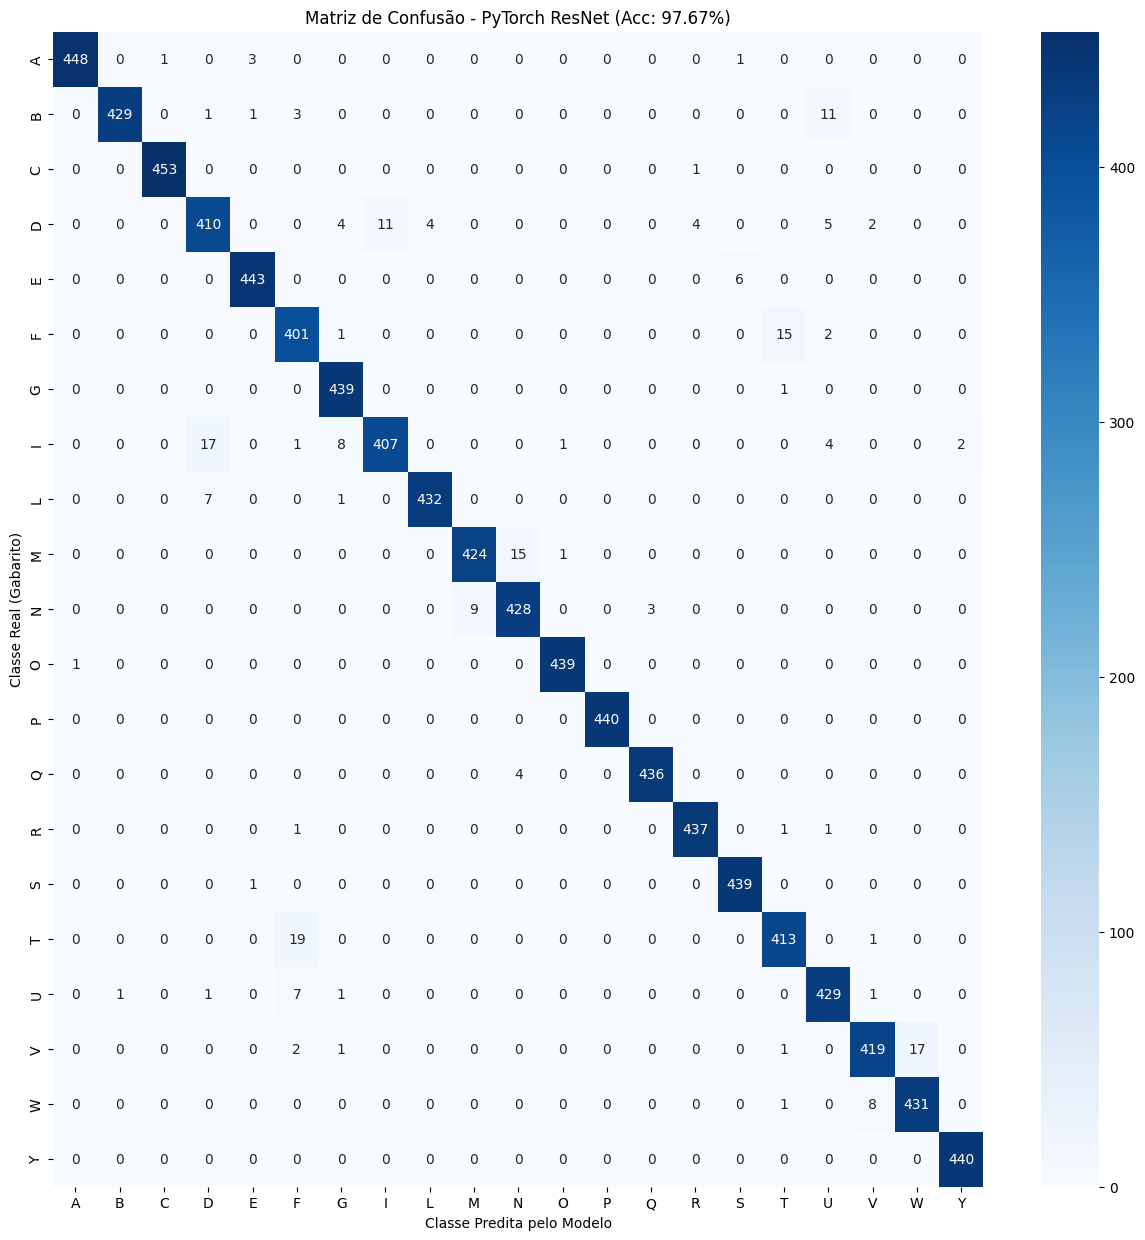


>>> RELATÓRIO DETALHADO POR LETRA:
              precision    recall  f1-score   support

           A       1.00      0.99      0.99       453
           B       1.00      0.96      0.98       445
           C       1.00      1.00      1.00       454
           D       0.94      0.93      0.94       440
           E       0.99      0.99      0.99       449
           F       0.92      0.96      0.94       419
           G       0.96      1.00      0.98       440
           I       0.97      0.93      0.95       440
           L       0.99      0.98      0.99       440
           M       0.98      0.96      0.97       440
           N       0.96      0.97      0.97       440
           O       1.00      1.00      1.00       440
           P       1.00      1.00      1.00       440
           Q       0.99      0.99      0.99       440
           R       0.99      0.99      0.99       440
           S       0.98      1.00      0.99       440
           T       0.96      0.95      0.95  

In [ ]:
# ==============================================================================
# 6. AVALIAÇÃO E VISUALIZAÇÃO DOS RESULTADOS (VERSÃO PYTORCH)
# ==============================================================================

print("-" * 40)
print(">>> AVALIAÇÃO FINAL (CONJUNTO DE TESTE)")
print("-" * 40)

def get_predictions(model, loader):
    model.eval() # Modo de avaliação (desliga dropout, batchnorm, etc)
    all_preds = []
    all_labels = []

    # Não calcula gradientes para economizar memória e ser rápido
    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc="Avaliando"):
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            # Move para CPU e converte para numpy
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_preds), np.array(all_labels)

# 1. Obter Previsões no Dataset de Teste (20% isolado)
y_pred, y_true = get_predictions(model_ft, test_loader)

# 2. Calcular Acurácia Global
accuracy = np.sum(y_pred == y_true) / len(y_true)
print(f"\n🎯 Acurácia Final no Teste: {accuracy*100:.2f}%")

# 3. Gerar Matriz de Confusão
print("\n>>> Gerando Matriz de Confusão...")
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 15))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Classe Real (Gabarito)')
plt.xlabel('Classe Predita pelo Modelo')
plt.title(f'Matriz de Confusão - PyTorch ResNet (Acc: {accuracy:.2%})')
plt.show()

# 4. Relatório Detalhado
print("\n>>> RELATÓRIO DETALHADO POR LETRA:")
print(classification_report(y_true, y_pred, target_names=class_names))

## Resultados

A comparação entre 10, 20 e 40 épocas e as limitações estão no [README](../../README.md).